<a href="https://colab.research.google.com/github/edirnolove/FDG-2026/blob/main/semana06/laboratorio06_individual.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LABORATORIO DIRIGIDO N.° 06 — AutoFlota Andina
**Fundamentos de Gestión de Datos | Semana 6 | 2026-II**

Limpieza de Auto MPG, SQLite, regresión lineal simple y múltiple, métricas, resúmenes estadísticos y diagnósticos. Ejecute todas las celdas en orden.

## A. Diagnóstico y limpieza

### Celda 1 — Preparación del entorno y carga de datos

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
columnas = ["rendimiento_mpg", "cilindros", "cilindrada", "potencia", "peso",
            "aceleracion", "anio_modelo", "codigo_origen", "nombre_auto"]
crudo = pd.read_csv(url, sep=r"\s+", names=columnas, na_values="?")
conexion = sqlite3.connect(":memory:")
crudo.to_sql("autos_original", conexion, index=False)
autos = pd.read_sql_query("SELECT * FROM autos_original;", conexion)
autos["marca"] = autos["nombre_auto"].str.split().str[0]
print("Filas y columnas:", autos.shape)

Filas y columnas: (398, 10)


### Celda 2 — Valores faltantes, duplicados y tipos

In [2]:
faltantes = autos.isna().sum()
print("Valores faltantes por columna (solo las que tienen):")
display(faltantes[faltantes > 0])
print("Filas duplicadas:", autos.duplicated().sum())
display(autos.dtypes)

Valores faltantes por columna (solo las que tienen):


,0
potencia,6


Filas duplicadas: 0


,0
rendimiento_mpg,float64
cilindros,int64
cilindrada,float64
potencia,float64
peso,float64
aceleracion,float64
anio_modelo,int64
codigo_origen,int64
nombre_auto,object
marca,object


**Preguntas del laboratorio**

**Pregunta 1.** ¿Qué problemas de calidad aparecen en la celda 2: faltantes, duplicados y tipos de dato?

**Respuesta:** Faltan 6 valores en potencia, no hay filas duplicadas (0) y los tipos son numéricos (float64 o int64), salvo nombre_auto y marca, que son texto (object). codigo_origen y anio_modelo son números aunque representan una categoría y un año.


### Celda 3 — Inconsistencias en marcas

In [3]:
variantes = ["vw", "vokswagen", "volkswagen", "chevy", "chevroelt", "chevrolet",
             "maxda", "mazda", "toyouta", "toyota", "mercedes", "mercedes-benz"]
display(autos[autos["marca"].isin(variantes)]["marca"].value_counts().sort_index())
print("Marcas distintas antes de corregir:", autos["marca"].nunique())

,count
marca,
chevroelt,1
chevrolet,43
chevy,3
maxda,2
mazda,10
mercedes,1
mercedes-benz,2
toyota,25
toyouta,1


Marcas distintas antes de corregir: 37


**Preguntas del laboratorio**

**Pregunta 2.** ¿Qué inconsistencia muestra la celda 3 en la columna marca y por qué afectaría a un groupby?

**Respuesta:** La misma marca está escrita de varias formas: vw, vokswagen y volkswagen; chevy, chevroelt y chevrolet; maxda y mazda; toyouta y toyota; mercedes y mercedes-benz. Hay 37 marcas distintas. El groupby las contaría como marcas diferentes y partiría los resultados.

### Celda 4 — Imputación de potencia

In [4]:
mediana = autos["potencia"].median()
promedio = autos["potencia"].mean()
print("Mediana de potencia:", mediana, "| promedio:", round(promedio, 2))
autos["potencia"] = autos["potencia"].fillna(mediana)
print("Faltantes en potencia después de imputar:", autos["potencia"].isna().sum())

Mediana de potencia: 93.5 | promedio: 104.47
Faltantes en potencia después de imputar: 0


**Preguntas del laboratorio**

**Pregunta 3.** ¿Por qué se imputa potencia con la mediana y no con el promedio? ¿Qué otra opción existía?

**Respuesta:** La mediana es 93.5 y el promedio 104.47. La mediana no se ve afectada por los valores muy altos, y el promedio sí se infla. Otra opción era eliminar las 6 filas con potencia faltante.

### Celda 5 — Origen, año y marcas

In [5]:
autos["origen"] = autos["codigo_origen"].map({1: "USA", 2: "Europa", 3: "Japón"})
autos["anio"] = 1900 + autos["anio_modelo"]
correcciones = {"vw": "volkswagen", "vokswagen": "volkswagen", "chevy": "chevrolet",
                "chevroelt": "chevrolet", "maxda": "mazda", "toyouta": "toyota",
                "mercedes": "mercedes-benz"}
autos["marca"] = autos["marca"].replace(correcciones)
print("Marcas distintas después de corregir:", autos["marca"].nunique())
display(autos[["nombre_auto", "marca", "origen", "anio"]].head())

Marcas distintas después de corregir: 30


,nombre_auto,marca,origen,anio
0,chevrolet chevelle malibu,chevrolet,USA,1970
1,buick skylark 320,buick,USA,1970
2,plymouth satellite,plymouth,USA,1970
3,amc rebel sst,amc,USA,1970
4,ford torino,ford,USA,1970


**Preguntas del laboratorio**

**Pregunta 4.** ¿Qué corrigen origen, anio y replace()? ¿Cuántas marcas distintas quedan?

**Respuesta:** origen cambia el código (1, 2, 3) por texto (USA, Europa, Japón). anio convierte el año de dos cifras a año completo (70 pasa a 1970). replace() unifica las marcas mal escritas. Quedan 30 marcas distintas.

### Celda 6 — Valores atípicos con IQR

In [6]:
q1 = autos["potencia"].quantile(0.25)
q3 = autos["potencia"].quantile(0.75)
iqr = q3 - q1
limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr
print("Q1:", q1, "| Q3:", q3, "| IQR:", iqr)
print("Límites:", round(limite_inf, 1), "y", round(limite_sup, 1))
atipicos = autos[(autos["potencia"] < limite_inf) | (autos["potencia"] > limite_sup)]
print("Autos atípicos en potencia:", len(atipicos))
display(atipicos[["nombre_auto", "potencia", "cilindros", "peso"]]
        .sort_values("potencia", ascending=False).head(5))

Q1: 76.0 | Q3: 125.0 | IQR: 49.0
Límites: 2.5 y 198.5
Autos atípicos en potencia: 11


,nombre_auto,potencia,cilindros,peso
116,pontiac grand prix,230.0,8,4278.0
13,buick estate wagon (sw),225.0,8,3086.0
8,pontiac catalina,225.0,8,4425.0
95,buick electra 225 custom,225.0,8,4951.0
6,chevrolet impala,220.0,8,4354.0


**Preguntas del laboratorio**

**Pregunta 5.** ¿Cuáles son los límites del IQR en potencia y cuántos autos los superan? ¿Por qué se conservan?

**Respuesta:** Los límites son 2.5 y 198.5 (Q1 = 76, Q3 = 125, IQR = 49). Los superan 11 autos, como el Pontiac Grand Prix con 230. Se conservan porque son autos reales de 8 cilindros y no errores de datos.

### Celda 7 — Boxplots y marca de atípicos

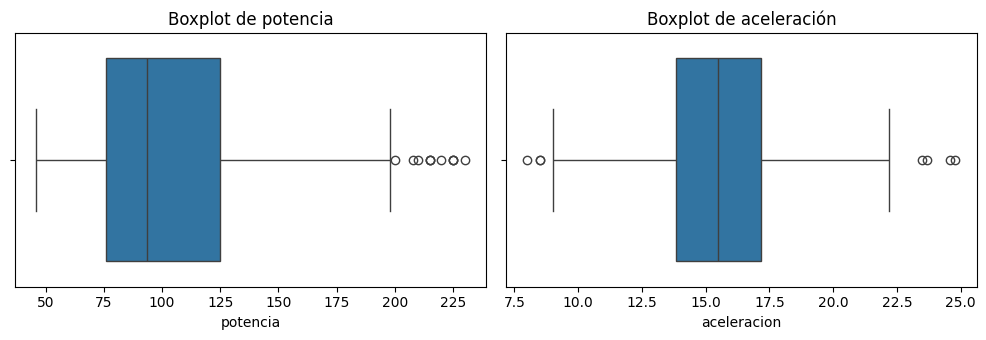

Autos marcados como atípicos (se conservan): 11


In [7]:
autos["potencia_atipica"] = (autos["potencia"] < limite_inf) | (autos["potencia"] > limite_sup)
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.boxplot(x=autos["potencia"], ax=ejes[0])
ejes[0].set_title("Boxplot de potencia")
sns.boxplot(x=autos["aceleracion"], ax=ejes[1])
ejes[1].set_title("Boxplot de aceleración")
plt.tight_layout()
plt.show()
print("Autos marcados como atípicos (se conservan):", autos["potencia_atipica"].sum())

**Preguntas del laboratorio**

**Pregunta 6.** ¿Qué muestran los boxplots de potencia y de aceleración?

**Respuesta:** Muestran la distribución de cada variable y sus valores atípicos, que se ven como puntos fuera de las líneas. En potencia hay puntos atípicos altos (los 11 autos sobre el límite). La aceleración también tiene algunos puntos atípicos.

### Celda 8 — Guardar datos limpios en SQLite

In [8]:
autos.to_sql("autos_limpio", conexion, index=False, if_exists="replace")
consulta = """SELECT
  (SELECT COUNT(*) FROM autos_original) AS filas_original,
  (SELECT COUNT(*) FROM autos_limpio) AS filas_limpio,
  (SELECT COUNT(*) FROM autos_original WHERE potencia IS NULL) AS faltantes_original,
  (SELECT COUNT(*) FROM autos_limpio WHERE potencia IS NULL) AS faltantes_limpio;"""
display(pd.read_sql_query(consulta, conexion))

,filas_original,filas_limpio,faltantes_original,faltantes_limpio
0,398,398,6,0


**Preguntas del laboratorio**

**Pregunta 7.** ¿Qué cambió entre autos_original y autos_limpio? ¿Por qué no se sobrescribe la tabla original?

**Respuesta:** Las dos tienen 398 filas, pero potencia tenía 6 faltantes en la original y 0 en la limpia. La limpia además tiene origen, anio, las marcas corregidas y la columna potencia_atipica. No se sobrescribe la original para conservar los datos tal como llegaron y poder repetir o comparar el proceso.

## B. Regresión lineal

### Celda 9 — Separación entrenamiento y prueba

In [9]:
y = autos["rendimiento_mpg"]
X_simple = autos[["peso"]]
X_train, X_test, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

Entrenamiento: (318, 1) | Prueba: (80, 1)


**Preguntas del laboratorio**

**Pregunta 8.** ¿Cuántos autos hay en entrenamiento y en prueba? ¿Para qué sirven la separación y random_state?

**Respuesta:** Hay 318 autos en entrenamiento y 80 en prueba. La separación permite evaluar el modelo con autos que no vio al aprender. random_state fija el sorteo para obtener siempre la misma división.

### Celda 10 — Regresión simple con scikit-learn

Coeficiente de peso: -0.00781
Intercepto: 46.78
{'R2': 0.723, 'MAE': 3.12, 'MSE': 14.89, 'RMSE': np.float64(3.86)}
                            OLS Regression Results                            
Dep. Variable:        rendimiento_mpg   R-squared:                       0.684
Model:                            OLS   Adj. R-squared:                  0.683
Method:                 Least Squares   F-statistic:                     685.5
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           3.80e-81
Time:                        23:39:09   Log-Likelihood:                -925.80
No. Observations:                 318   AIC:                             1856.
Df Residuals:                     316   BIC:                             1863.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
----------------

,coeficiente,p_valor,IC_95_inf,IC_95_sup
const,46.782063,3.145697e-154,44.972403,48.591724
peso,-0.007805,3.799579e-81,-0.008392,-0.007219


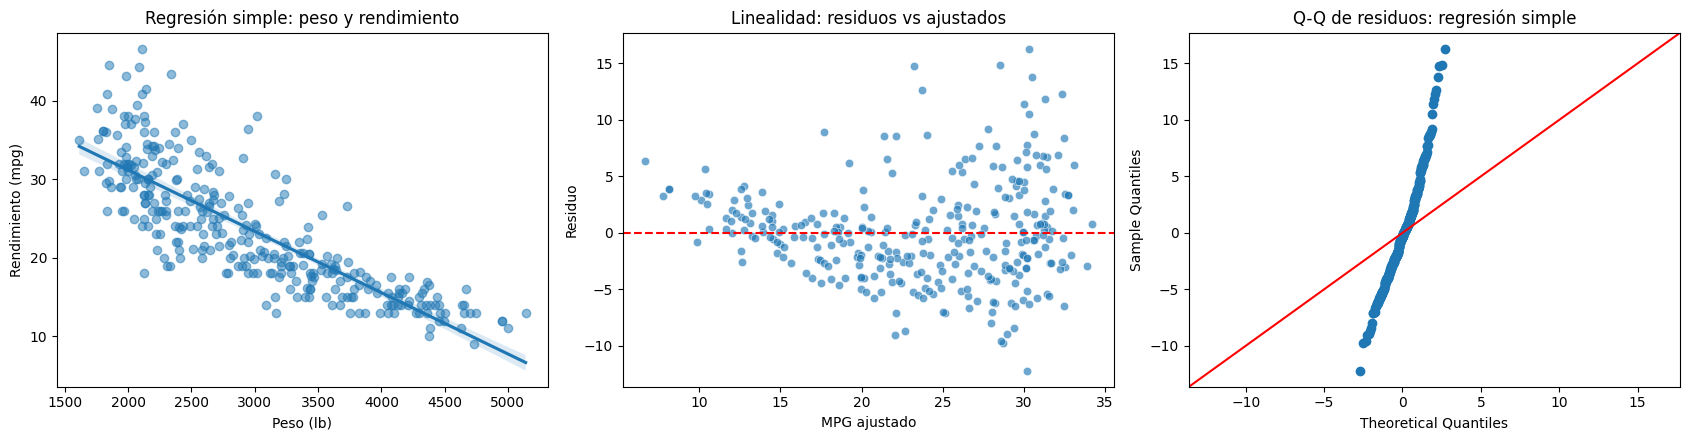

                            OLS Regression Results                            
Dep. Variable:        rendimiento_mpg   R-squared:                       0.684
Model:                            OLS   Adj. R-squared:                  0.683
Method:                 Least Squares   F-statistic:                     685.5
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           3.80e-81
Time:                        23:39:10   Log-Likelihood:                -925.80
No. Observations:                 318   AIC:                             1856.
Df Residuals:                     316   BIC:                             1863.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         46.7821      0.920     50.862      0.0

In [10]:
def metricas(y_real, y_pred):
    mse = mean_squared_error(y_real, y_pred)
    return {"R2": round(r2_score(y_real, y_pred), 3),
            "MAE": round(mean_absolute_error(y_real, y_pred), 2),
            "MSE": round(mse, 2),
            "RMSE": round(np.sqrt(mse), 2)}

modelo_simple = LinearRegression()
modelo_simple.fit(X_train, y_train)
pred_simple = modelo_simple.predict(X_test)
print("Coeficiente de peso:", round(modelo_simple.coef_[0], 5))
print("Intercepto:", round(modelo_simple.intercept_, 2))
res_simple = metricas(y_test, pred_simple)
print(res_simple)

# Resumen estadístico, coeficientes y p-valores (regresión simple)
import statsmodels.api as sm
X_simple_sm = sm.add_constant(X_train)
modelo_simple_sm = sm.OLS(y_train, X_simple_sm).fit()
print(modelo_simple_sm.summary())
print("\nCoeficientes y p-valores (entrenamiento):")
display(pd.DataFrame({"coeficiente": modelo_simple_sm.params,
                      "p_valor": modelo_simple_sm.pvalues,
                      "IC_95_inf": modelo_simple_sm.conf_int()[0],
                      "IC_95_sup": modelo_simple_sm.conf_int()[1]}))

# Gráficas de linealidad, residuos y Q-Q (regresión simple)
ajustados_simple = modelo_simple_sm.fittedvalues
residuos_simple = modelo_simple_sm.resid
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.regplot(x=X_train["peso"], y=y_train, ax=ejes[0], scatter_kws={"alpha": 0.5})
ejes[0].set(title="Regresión simple: peso y rendimiento", xlabel="Peso (lb)", ylabel="Rendimiento (mpg)")
sns.scatterplot(x=ajustados_simple, y=residuos_simple, ax=ejes[1], alpha=0.65)
ejes[1].axhline(0, color="red", linestyle="--")
ejes[1].set(title="Linealidad: residuos vs ajustados", xlabel="MPG ajustado", ylabel="Residuo")
sm.qqplot(residuos_simple, line="45", ax=ejes[2])
ejes[2].set_title("Q-Q de residuos: regresión simple")
plt.tight_layout()
plt.show()

# Summary: coeficientes y p-valores de la regresión simple
import statsmodels.api as sm
modelo_simple_sm = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(modelo_simple_sm.summary())


**Preguntas del laboratorio**

**Pregunta 9.** Interprete el coeficiente de peso, el intercepto y las cuatro métricas del modelo simple.

**Respuesta:** El coeficiente de peso es −0.00781: por cada libra más, el rendimiento baja 0.0078 mpg (unos 7.8 mpg menos por cada 1000 libras). El intercepto es 46.78, el punto de partida de la recta. R² = 0.723: explica el 72.3 % de la variación. MAE = 3.12: se equivoca 3.12 mpg en promedio. MSE = 14.89 y RMSE = 3.86 mpg: el error típico, en las mismas unidades que el rendimiento.

### Celda 11 — Regresión múltiple con scikit-learn

,variable,coeficiente
0,peso,-0.0070
1,potencia,0.0027
2,cilindrada,0.0026
3,aceleracion,0.0797
4,anio,0.8008


Intercepto: -1539.97
{'R2': 0.826, 'MAE': 2.46, 'MSE': 9.38, 'RMSE': np.float64(3.06)}
                            OLS Regression Results                            
Dep. Variable:        rendimiento_mpg   R-squared:                       0.804
Model:                            OLS   Adj. R-squared:                  0.801
Method:                 Least Squares   F-statistic:                     255.8
Date:                Sun, 08 Nov 2026   Prob (F-statistic):          4.62e-108
Time:                        23:39:18   Log-Likelihood:                -850.20
No. Observations:                 318   AIC:                             1712.
Df Residuals:                     312   BIC:                             1735.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------

,coeficiente,p_valor,IC_95_inf,IC_95_sup
const,-1539.973203,2.340422e-29,-1782.300119,-1297.646287
peso,-0.007029,1.572087e-18,-0.008506,-0.005552
potencia,0.002657,8.646462e-01,-0.027988,0.033302
cilindrada,0.002625,6.714209e-01,-0.009540,0.014790
aceleracion,0.079661,4.831939e-01,-0.143612,0.302933
anio,0.800782,9.879430e-31,0.678449,0.923114


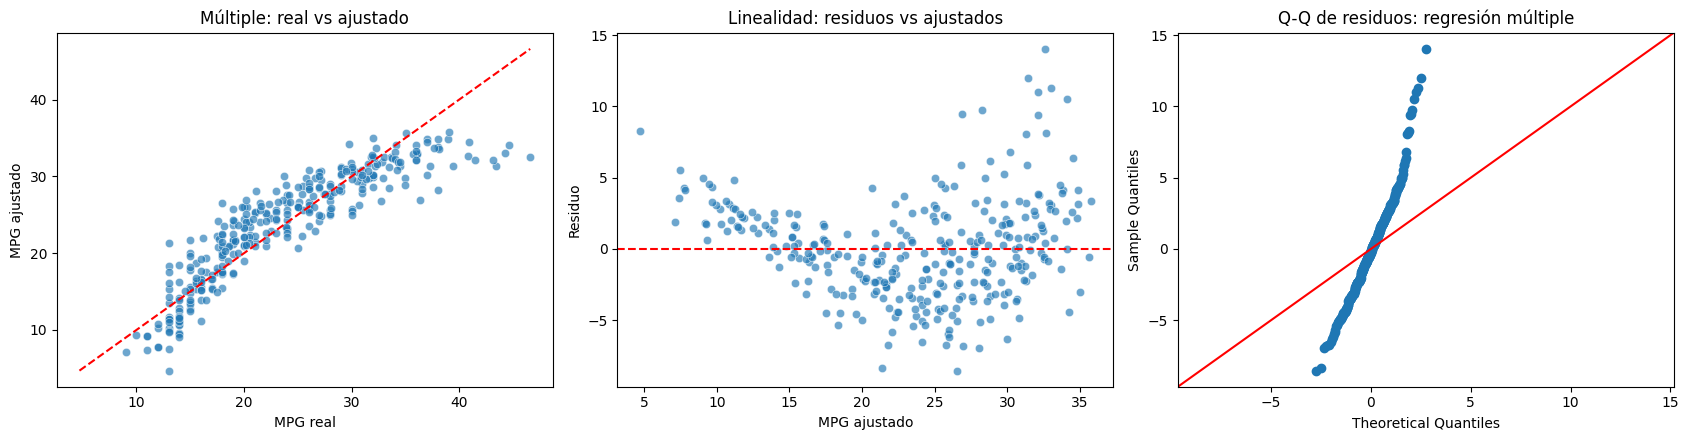

In [11]:
variables = ["peso", "potencia", "cilindrada", "aceleracion", "anio"]
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    autos[variables], y, test_size=0.2, random_state=42)
modelo_multiple = LinearRegression()
modelo_multiple.fit(Xm_train, ym_train)
pred_multiple = modelo_multiple.predict(Xm_test)
display(pd.DataFrame({"variable": variables, "coeficiente": modelo_multiple.coef_.round(4)}))
print("Intercepto:", round(modelo_multiple.intercept_, 2))
res_multiple = metricas(ym_test, pred_multiple)
print(res_multiple)

# Resumen estadístico, coeficientes y p-valores (regresión múltiple)
Xm_const = sm.add_constant(Xm_train)
modelo_multiple_sm = sm.OLS(ym_train, Xm_const).fit()
print(modelo_multiple_sm.summary())
print("\nCoeficientes y p-valores (entrenamiento):")
display(pd.DataFrame({"coeficiente": modelo_multiple_sm.params,
                      "p_valor": modelo_multiple_sm.pvalues,
                      "IC_95_inf": modelo_multiple_sm.conf_int()[0],
                      "IC_95_sup": modelo_multiple_sm.conf_int()[1]}))

# Gráficas de linealidad, residuos y Q-Q (regresión múltiple)
ajustados_multiple = modelo_multiple_sm.fittedvalues
residuos_multiple = modelo_multiple_sm.resid
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(x=ym_train, y=ajustados_multiple, ax=ejes[0], alpha=0.65)
limites = [min(ym_train.min(), ajustados_multiple.min()), max(ym_train.max(), ajustados_multiple.max())]
ejes[0].plot(limites, limites, "r--")
ejes[0].set(title="Múltiple: real vs ajustado", xlabel="MPG real", ylabel="MPG ajustado")
sns.scatterplot(x=ajustados_multiple, y=residuos_multiple, ax=ejes[1], alpha=0.65)
ejes[1].axhline(0, color="red", linestyle="--")
ejes[1].set(title="Linealidad: residuos vs ajustados", xlabel="MPG ajustado", ylabel="Residuo")
sm.qqplot(residuos_multiple, line="45", ax=ejes[2])
ejes[2].set_title("Q-Q de residuos: regresión múltiple")
plt.tight_layout()
plt.show()



**Preguntas del laboratorio**

**Pregunta 10.** Interprete los coeficientes del modelo múltiple. ¿Qué llama la atención en potencia y por qué?

**Respuesta:** Peso es -0.0070 (más peso, menos mpg). Potencia es 0.0027, cilindrada 0.0026, aceleración 0.0797 y anio 0.8008 (cada año más nuevo suma unos 0.8 mpg). Llama la atención que potencia sea positiva, cuando se esperaría que más potencia baje el rendimiento. Pasa porque potencia, peso y cilindrada están muy relacionadas y el modelo reparte el efecto entre ellas.

### Celda 12 — Comparación de modelos y gráfica de prueba

,simple (peso),múltiple (5 variables)
R2,0.723,0.826
MAE,3.120,2.460
MSE,14.890,9.380
RMSE,3.860,3.060


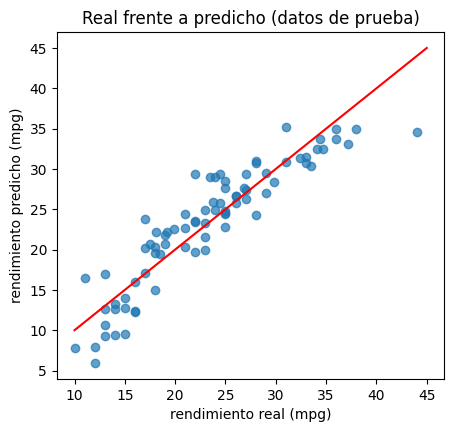

In [12]:
comparacion = pd.DataFrame({"simple (peso)": res_simple,
                           "múltiple (5 variables)": res_multiple})
display(comparacion)
plt.figure(figsize=(5, 4.5))
plt.scatter(ym_test, pred_multiple, alpha=0.7)
plt.plot([10, 45], [10, 45], color="red")
plt.xlabel("rendimiento real (mpg)")
plt.ylabel("rendimiento predicho (mpg)")
plt.title("Real frente a predicho (datos de prueba)")
plt.show()

**Preguntas del laboratorio**

**Pregunta 11.** Compare las métricas de los dos modelos. ¿Cuál es mejor y por qué se compara con los datos de prueba?

**Respuesta:** El múltiple es mejor: R² 0.826 frente a 0.723, MAE 2.46 frente a 3.12 y RMSE 3.06 frente a 3.86. Se compara con los datos de prueba porque muestran cómo responde con autos nuevos y no solo con los que ya conocía.

## Actividad 3 — Predicción para la flota

### Celda 13 — Candidatos de compra

In [13]:
candidatos = pd.DataFrame({
    "candidato": ["A", "B", "C"],
    "peso": [2200, 3000, 4200],
    "potencia": [80, 110, 160],
    "cilindrada": [100, 200, 350],
    "aceleracion": [16, 15, 12],
    "anio": [1982, 1980, 1978]})
candidatos["rendimiento_predicho"] = modelo_multiple.predict(candidatos[variables]).round(1)
display(candidatos)

,candidato,peso,potencia,cilindrada,aceleracion,anio,rendimiento_predicho
0,A,2200,80,100,16,1982,33.5
1,B,3000,110,200,15,1980,26.5
2,C,4200,160,350,12,1978,16.7


**Preguntas del laboratorio**

**A.** ¿Qué candidato rinde más y cuál menos? ¿Qué características lo explican?

**Respuesta:** El candidato A rinde más (33.5 mpg) y el C menos (16.7 mpg). A es liviano (2200 lb), de poca potencia (80) y más nuevo (1982). C es pesado (4200 lb), potente (160) y más antiguo (1978).

**B.** Redacte una recomendación para AutoFlota Andina e indique los límites del modelo.

**Respuesta:** Recomiendo el candidato A porque consume menos. Los límites: el modelo usa autos de 1970 a 1982, que no son los de hoy; su R² es 0.826, así que no explica todo; se equivoca unos 3.06 mpg en promedio; y no considera el costo ni el mantenimiento.

## Retos de aplicación

### Celda 14 — Reto 1: variables por separado

In [14]:
resultados = []
for variable in ["peso", "potencia", "cilindrada", "aceleracion", "anio"]:
    Xv_train, Xv_test, yv_train, yv_test = train_test_split(
        autos[[variable]], y, test_size=0.2, random_state=42)
    modelo = LinearRegression().fit(Xv_train, yv_train)
    resultados.append({"variable": variable,
                       "coeficiente": round(modelo.coef_[0], 4),
                       **metricas(yv_test, modelo.predict(Xv_test))})
tabla_simples = pd.DataFrame(resultados).sort_values("R2", ascending=False)
display(tabla_simples)

,variable,coeficiente,R2,MAE,MSE,RMSE
0,peso,-0.0078,0.723,3.12,14.89,3.86
2,cilindrada,-0.0617,0.663,3.39,18.10,4.25
1,potencia,-0.1640,0.640,3.51,19.37,4.40
4,anio,1.2914,0.287,5.36,38.32,6.19
3,aceleracion,1.1196,0.284,4.99,38.51,6.21


**Preguntas del laboratorio**

**Pregunta de cierre.** ¿Qué variable explica mejor el rendimiento por sí sola y cuál peor? Sustente con R² y RMSE e interprete el signo de los coeficientes.

**Respuesta:** La que mejor explica es el peso (R² 0.723, RMSE 3.86) y la que peor es la aceleración (R² 0.284, RMSE 6.21). Peso, cilindrada y potencia tienen coeficiente negativo: más grandes, menos rendimiento. Anio y aceleración tienen coeficiente positivo: autos más nuevos y más lentos rinden más.

### Celda 15 — Reto 2: combinaciones de variables

In [15]:
dummies = pd.get_dummies(autos["origen"], prefix="origen", drop_first=True).astype(int)
X_todo = pd.concat([autos[variables], dummies], axis=1)
combinaciones = {
    "peso + anio": ["peso", "anio"],
    "peso + potencia + anio": ["peso", "potencia", "anio"],
    "5 variables": variables,
    "5 variables + origen": list(X_todo.columns),
}
filas = []
for nombre, columnas_x in combinaciones.items():
    Xc_train, Xc_test, yc_train, yc_test = train_test_split(
        X_todo[columnas_x], y, test_size=0.2, random_state=42)
    modelo = LinearRegression().fit(Xc_train, yc_train)
    r = metricas(yc_test, modelo.predict(Xc_test))
    n, p = len(yc_test), len(columnas_x)
    r["R2_ajustado"] = round(1 - (1 - r["R2"]) * (n - 1) / (n - p - 1), 3)
    filas.append({"modelo": nombre, "variables": p, **r})
modelo_origen = modelo
print(dict(zip(X_todo.columns, modelo_origen.coef_.round(3))))
tabla_combos = pd.DataFrame(filas)
display(tabla_combos)

{'peso': np.float64(-0.007), 'potencia': np.float64(-0.014), 'cilindrada': np.float64(0.017), 'aceleracion': np.float64(0.07), 'anio': np.float64(0.827), 'origen_Japón': np.float64(-0.294), 'origen_USA': np.float64(-2.925)}


,modelo,variables,R2,MAE,MSE,RMSE,R2_ajustado
0,peso + anio,2,0.824,2.45,9.44,3.07,0.819
1,peso + potencia + anio,3,0.824,2.45,9.44,3.07,0.817
2,5 variables,5,0.826,2.46,9.38,3.06,0.814
3,5 variables + origen,7,0.843,2.29,8.47,2.91,0.828


**Preguntas del laboratorio**

**Pregunta de cierre.** ¿Qué combinación tiene el mayor R² ajustado? ¿Cuánto aporta agregar el origen y cuál es su categoría de referencia?

**Respuesta:** La combinación con mayor R² ajustado es "5 variables + origen" (0.828). Agregar el origen sube el R² de 0.826 a 0.843, el R² ajustado de 0.814 a 0.828 y baja el RMSE de 3.06 a 2.91. La categoría de referencia es Europa, que se omitió al crear las variables indicadoras.

### Celda 16 — Reto 3: imputar o eliminar

In [16]:
original = pd.read_sql_query(
    "SELECT * FROM autos_original WHERE potencia IS NOT NULL;", conexion)
original["anio"] = 1900 + original["anio_modelo"]
Xe_train, Xe_test, ye_train, ye_test = train_test_split(
    original[variables], original["rendimiento_mpg"], test_size=0.2, random_state=42)
modelo_sin = LinearRegression().fit(Xe_train, ye_train)
print("Filas usadas:", len(original), "frente a", len(autos))
print("Eliminando faltantes:", metricas(ye_test, modelo_sin.predict(Xe_test)))
print("Imputando mediana: ", res_multiple)

Filas usadas: 392 frente a 398
Eliminando faltantes: {'R2': 0.793, 'MAE': 2.51, 'MSE': 10.58, 'RMSE': np.float64(3.25)}
Imputando mediana:  {'R2': 0.826, 'MAE': 2.46, 'MSE': 9.38, 'RMSE': np.float64(3.06)}


**Preguntas del laboratorio**

**Pregunta de cierre.** ¿Cuántos autos usa cada opción y cómo cambian las métricas? ¿Por qué la comparación debe hacerse con cuidado?

**Respuesta:** Eliminar usa 392 autos e imputar usa 398. Eliminando: R²: 0.793, MAE: 2.51 y RMSE: 3.25. Imputando: R²: 0.826, MAE: 2.46 y RMSE: 3.06. Hay que comparar con cuidado porque, al tener distinto número de autos, los datos de prueba no son los mismos en ambos casos.

### Conclusiones

Escriba tres conclusiones técnicas y de negocio de este laboratorio.

1. La limpieza fue necesaria antes del modelo: había 6 valores faltantes en potencia, marcas mal escritas (37 distintas, quedaron 30) y 11 autos atípicos que se conservaron por ser casos reales.

2. La regresión múltiple predijo mejor que la simple (R² 0.826 frente a 0.723 y RMSE 3.06 frente a 3.86), y evaluar con datos de prueba permite saber si el modelo funciona con autos nuevos.

3. Para AutoFlota Andina, el modelo estima que el candidato A rinde más (33.5 mpg) y el C menos (16.7 mpg). Aun así, los datos son de 1970 a 1982 y el error típico es de 3.06 mpg, así que la decisión necesita información más actual.